In [123]:
import pandas as pd
import sqlite3

conn = sqlite3.connect("../data/checking-logs.sqlite")

In [124]:
dfChecks = pd.io.sql.read_sql(
    """SELECT date(timestamp) as date, strftime('%H', timestamp) as hour FROM checker
        WHERE uid NOT LIKE 'admin_%'""",
    conn,
)

dfChecks["date"] = pd.to_datetime(dfChecks["date"])
dfChecks["hour"] = dfChecks["hour"].astype("int8")
dfChecks["day_type"] = dfChecks["date"].dt.dayofweek.apply(
    lambda x: "weekend" if x >= 5 else "working_day"
)
dfChecks

,date,hour,day_type
0,2020-04-17,5,working_day
1,2020-04-17,5,working_day
2,2020-04-17,5,working_day
3,2020-04-17,5,working_day
4,2020-04-17,5,working_day
...,...,...,...
3202,2020-05-21,20,working_day
3203,2020-05-21,20,working_day
3204,2020-05-21,20,working_day
3205,2020-05-21,20,working_day


In [125]:
dfChecks = (
    dfChecks.groupby(["day_type", "date", "hour"]).size().reset_index(name="commits")
)
dfChecks

,day_type,date,hour,commits
0,weekend,2020-04-18,7,1
1,weekend,2020-04-18,13,5
2,weekend,2020-04-18,14,3
3,weekend,2020-04-18,15,25
4,weekend,2020-04-18,17,7
...,...,...,...,...
283,working_day,2020-05-21,16,4
284,working_day,2020-05-21,17,1
285,working_day,2020-05-21,18,2
286,working_day,2020-05-21,19,8


In [126]:
dfChecksCommsAvg = (
    dfChecks.groupby(["day_type", "hour"])["commits"].mean().reset_index()
)
dfChecksCommsAvg.head()

,day_type,hour,commits
0,weekend,0,2.0
1,weekend,1,6.0
2,weekend,3,1.0
3,weekend,5,2.0
4,weekend,7,4.0


In [127]:
max_hour_weekend = dfChecksCommsAvg[dfChecksCommsAvg["day_type"] == "weekend"].loc[
    lambda x: x["commits"].idxmax(), "hour"
]

max_hour_days = dfChecksCommsAvg[dfChecksCommsAvg["day_type"] == "working_day"].loc[
    lambda x: x["commits"].idxmax(), "hour"
]

print(f"Максимальный час  в выходные: {max_hour_weekend}")
print(f"Максимальный час  в будни: {max_hour_days}")

Максимальный час  в выходные: 11
Максимальный час  в будни: 21


In [128]:
ch_pvt = dfChecksCommsAvg.pivot(index="hour", columns="day_type", values="commits")
ch_pvt = ch_pvt.reindex(range(24))

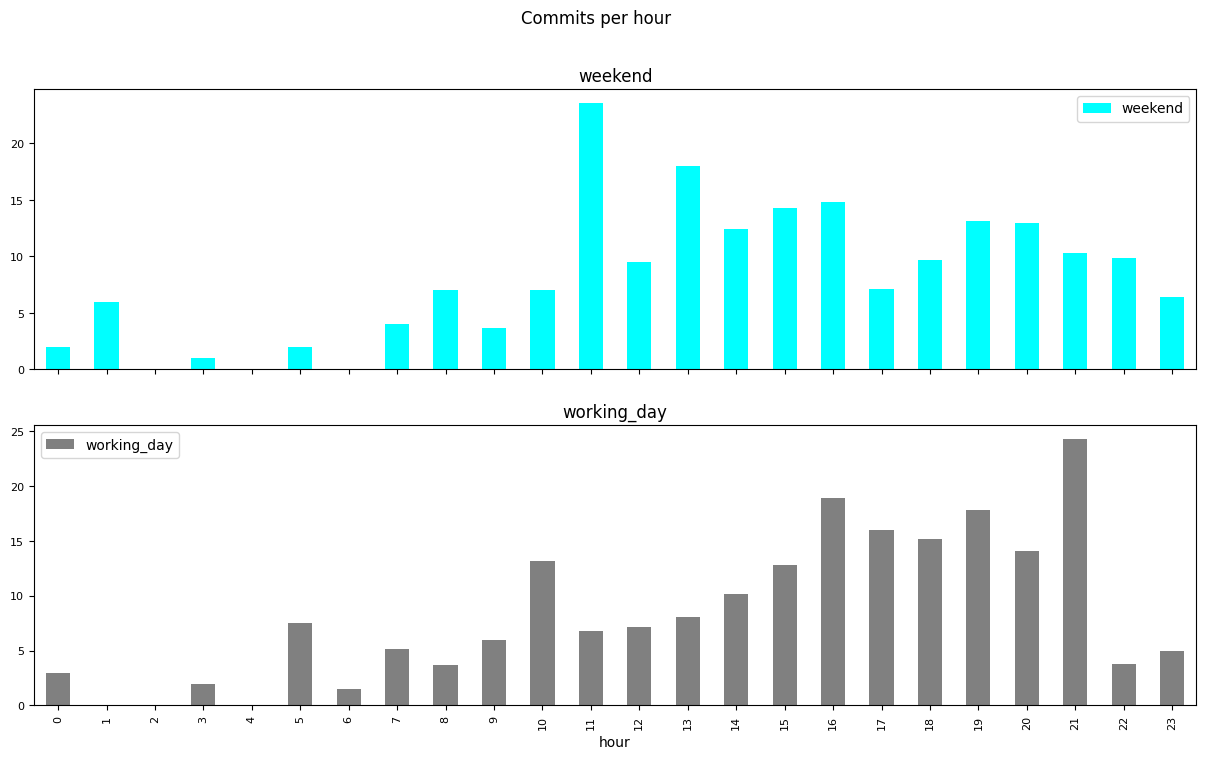

In [129]:
pl = ch_pvt.plot(
    kind="bar",
    subplots=True,
    figsize=(15, 8),
    fontsize=8,
    title=["weekend", "working_day"],
    color=["cyan", "grey"],
)

pl[0].figure.suptitle("Commits per hour");

## Различается ли динамика в рабочие дни и в выходные?
 
 Да, динамика несомненно отличается: мы наблюдаем наибольшее число коммитов в рабочие дни в районе 21 часа, то есть вечером, что логично для раотающих людей, тогда как в выходные имеем топовое число коммитов в 11 утра.

In [ ]:
conn.close()